[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[![VGI](assets/vgi-logo.png)](https://query.farm/vgi/)

# Rebuild a directory from its changes

How many users remain after an incremental directory scan? Counting returned rows is insufficient: updates replace existing users, removals carry only an ID, and a cursor marker is a control row. We retrieve two synthetic snapshots through the real VGI function, apply their changes in SQL, and verify that retrying the same delta leaves the resulting state unchanged.

**Synthetic fixture, no live tenant.** The companion uses the project’s existing `makeDeltaFunction(spec, clientFactory)` injection interface and its tested `FakeGraph` source. The actual pinned worker supplies paging, row conversion, schemas and VGI transport. Its authentication and live Microsoft Graph transport are intentionally replaced by the explicit synthetic client. Names and `example.invalid` addresses are invented. This does not validate a tenant’s permissions or live API behavior.

## Change the number of removals

`REMOVED_USERS` is either 1 or 2. Both runs start with the same six users, disable one existing account, add two users and remove the selected number of original users. The helper serves pages of two source objects, so both scans exercise pagination. Restart and run all after changing the parameter.

In [1]:
REMOVED_USERS = 1  # synthetic users removed between snapshots; integer 1 or 2

In [2]:
import os

import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from notebook_support import finish, prose, theme

if type(REMOVED_USERS) is not int or REMOVED_USERS not in (1, 2):
    raise ValueError("REMOVED_USERS must be the integer 1 or 2.")
os.environ["NOTEBOOK_REMOVALS"] = str(REMOVED_USERS)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-azure-directory/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-azure-directory/notebooks/pyproject.toml.

## Load the pinned functions with the synthetic client

The visible launcher fetches the exact public Git revision, verifies its commit, installs the frozen Bun lock and imports the existing user-delta function. The fixture harness only supplies its Graph client and the invented snapshots; it performs no network calls to Azure. The dummy secret satisfies the real function’s secret requirement. The [README](README.md) explains this launch mode and its limits.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'azure' (TYPE vgi,
    LOCATION 'bun run fixture_worker.ts Query-farm/vgi-azure-directory 9c2dcde4df370127818d7e88ecfb1143a4f093e8'
);
CREATE SECRET synthetic_directory (
    TYPE azure_graph, TENANT_ID 'fixture', CLIENT_ID 'fixture', CLIENT_SECRET 'fixture'
);

,Success


## Capture the full scan, including its marker

A scan is materialized once before inspection. Data rows have a NULL `_row_kind`; exactly one trailing marker holds `_delta_next`. The marker’s NULL account fields are unavailable values, so it must be excluded from user counts.

In [4]:
%%sql
CREATE TABLE full_scan AS
SELECT * FROM azure.main.directory_users_delta();

SELECT id, change_type, account_enabled, _row_kind, _delta_next
FROM full_scan ORDER BY id NULLS LAST;

,id,change_type,account_enabled,_row_kind,_delta_next
0,synthetic-user-1,upsert,True,None,None
1,synthetic-user-2,upsert,True,None,None
2,synthetic-user-3,upsert,True,None,None
3,synthetic-user-4,upsert,True,None,None
4,synthetic-user-5,upsert,True,None,None
5,synthetic-user-6,upsert,False,None,None
6,None,None,<NA>,marker,https://graph.microsoft.com/v1.0/users/delta?$...


## Initialize a local state and checkpoint

The primary key makes user identity explicit. We apply the data rows before saving the cursor. This walkthrough uses **in-memory** tables; these sequential statements demonstrate state/checkpoint ordering, not an atomic or durable sink. JupySQL uses separate cursors for statements. A production sink must durably commit state and checkpoint together before acknowledging the new cursor.

In [5]:
%%sql
CREATE TABLE local_users (
    id VARCHAR PRIMARY KEY,
    user_principal_name VARCHAR,
    display_name VARCHAR,
    account_enabled BOOLEAN
);
CREATE TABLE checkpoint (delta_token VARCHAR);

INSERT INTO local_users
SELECT id, user_principal_name, display_name, account_enabled
FROM full_scan WHERE _row_kind IS NULL AND change_type = 'upsert';
INSERT INTO checkpoint
SELECT _delta_next FROM full_scan WHERE _row_kind = 'marker';

CREATE TABLE initial_users AS SELECT * FROM local_users;
SELECT * FROM local_users ORDER BY id;

,id,user_principal_name,display_name,account_enabled
0,synthetic-user-1,user1@example.invalid,Synthetic user 1,True
1,synthetic-user-2,user2@example.invalid,Synthetic user 2,True
2,synthetic-user-3,user3@example.invalid,Synthetic user 3,True
3,synthetic-user-4,user4@example.invalid,Synthetic user 4,True
4,synthetic-user-5,user5@example.invalid,Synthetic user 5,True
5,synthetic-user-6,user6@example.invalid,Synthetic user 6,False


In [6]:
%%sql cursor_frame <<
SELECT delta_token FROM checkpoint;

In [7]:
assert len(cursor_frame) == 1, "Expected one checkpoint."
cursor = str(cursor_frame.iloc[0].delta_token)

## Read the next window using the returned cursor

The small hidden Python cell above only moves the SQL-returned cursor into the literal function argument; the engine requires a scalar argument here. Its value is used verbatim. For this synthetic source, that cursor selects the prepared later snapshot.

In [8]:
%%sql
CREATE TABLE delta_scan AS
SELECT * FROM azure.main.directory_users_delta(delta_token := '{{cursor}}');

SELECT id, change_type, removed_reason, account_enabled, _row_kind, _delta_next
FROM delta_scan ORDER BY id NULLS LAST;

,id,change_type,removed_reason,account_enabled,_row_kind,_delta_next
0,synthetic-user-1,removed,deleted,<NA>,None,None
1,synthetic-user-3,upsert,None,False,None,None
2,synthetic-user-7,upsert,None,True,None,None
3,synthetic-user-8,upsert,None,False,None,None
4,None,None,None,<NA>,marker,https://graph.microsoft.com/v1.0/users/delta?$...


## Distinguish new users, updates, removals and markers

An upsert’s ID tells us whether it replaces a known user or adds one. Join the delta to the initial state before applying it. Only additions and removals change the headcount; an update may change attributes without changing the number of users.

In [9]:
%%sql changes <<
WITH classified AS (
    SELECT CASE
        WHEN d._row_kind = 'marker' THEN 'Cursor marker'
        WHEN d.change_type = 'removed' THEN 'Removed user'
        WHEN i.id IS NULL THEN 'New user'
        ELSE 'Existing-user update'
    END AS row_meaning
    FROM delta_scan d LEFT JOIN initial_users i ON d.id = i.id
)
SELECT row_meaning, count(*) AS rows
FROM classified GROUP BY row_meaning ORDER BY row_meaning;

In [10]:
display(changes)

,row_meaning,rows
0,Cursor marker,1
1,Existing-user update,1
2,New user,2
3,Removed user,1


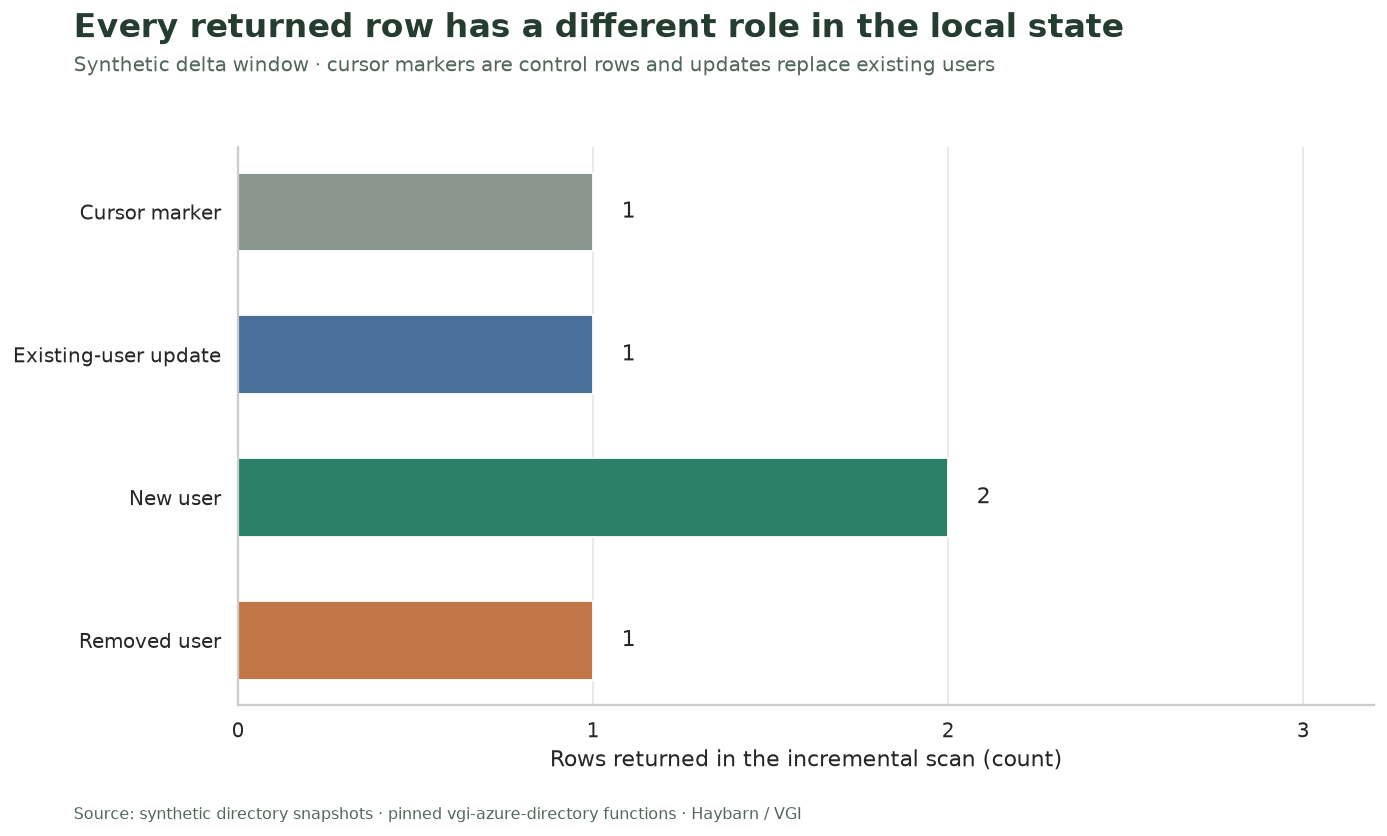

In [11]:
colors = {
    "Cursor marker": "#8b9690",
    "Existing-user update": "#4a6f9b",
    "New user": "#2b8067",
    "Removed user": "#c47548",
}
fig, ax = plt.subplots(figsize=(11.5, 6.5))
y = np.arange(len(changes))
ax.barh(y, changes.rows, color=[colors[x] for x in changes.row_meaning], height=0.55)
for i, row in changes.iterrows():
    ax.text(row.rows + 0.08, i, str(row.rows), va="center")
ax.set_yticks(y, changes.row_meaning)
ax.invert_yaxis()
ax.set_xlabel("Rows returned in the incremental scan (count)")
ax.set_xlim(0, int(changes.rows.max()) + 1.2)
ax.set_xticks(range(int(changes.rows.max()) + 2))
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Every returned row has a different role in the local state",
    "Synthetic delta window · cursor markers are control rows and updates replace existing users",
    f"changes-removals-{REMOVED_USERS}.png",
)

## Apply the delta and advance the checkpoint

Remove tombstoned IDs, replace or insert upserts, then store the new cursor after those local state changes. Deleted rows have NULL business fields; those NULLs must not overwrite a retained user. The SQL filters the change types explicitly.

In [12]:
%%sql
DELETE FROM local_users
USING delta_scan d
WHERE local_users.id = d.id AND d._row_kind IS NULL AND d.change_type = 'removed';

INSERT OR REPLACE INTO local_users
SELECT id, user_principal_name, display_name, account_enabled
FROM delta_scan WHERE _row_kind IS NULL AND change_type = 'upsert';

UPDATE checkpoint SET delta_token = (
    SELECT _delta_next FROM delta_scan WHERE _row_kind = 'marker'
);

CREATE TABLE applied_once AS SELECT * FROM local_users;
SELECT id, display_name, account_enabled FROM local_users ORDER BY id;

,id,display_name,account_enabled
0,synthetic-user-2,Synthetic user 2,True
1,synthetic-user-3,Synthetic user 3,False
2,synthetic-user-4,Synthetic user 4,True
3,synthetic-user-5,Synthetic user 5,True
4,synthetic-user-6,Synthetic user 6,False
5,synthetic-user-7,Synthetic user 7,True
6,synthetic-user-8,Synthetic user 8,False


In [13]:
%%sql balance <<
SELECT
    (SELECT count(*) FROM initial_users) AS initial_users,
    (SELECT count(*) FROM delta_scan d LEFT JOIN initial_users i ON d.id = i.id
        WHERE d._row_kind IS NULL AND d.change_type = 'upsert' AND i.id IS NULL) AS added_users,
    (SELECT count(*) FROM delta_scan WHERE _row_kind IS NULL AND change_type = 'removed') AS removed_users,
    (SELECT count(*) FROM delta_scan WHERE _row_kind IS NULL) AS change_rows,
    (SELECT count(*) FROM local_users) AS current_users;

In [14]:
b = balance.iloc[0]
prose(
    f"The scan returned **{int(b.change_rows)} change rows**, while the reconstructed directory contains "
    f"**{int(b.current_users)} users**: initial {int(b.initial_users)} + "
    f"added {int(b.added_users)} − removed {int(b.removed_users)}. "
    "An existing-user update affects the account-status distribution without adding a user."
)

The scan returned **4 change rows**, while the reconstructed directory contains **7 users**: initial 6 + added 2 − removed 1. An existing-user update affects the account-status distribution without adding a user.

In [15]:
%%sql states <<
SELECT 'Initial' AS snapshot,
       count(*) FILTER (WHERE account_enabled IS TRUE) AS enabled,
       count(*) FILTER (WHERE account_enabled IS FALSE) AS disabled,
       count(*) FILTER (WHERE account_enabled IS NULL) AS unknown,
       count(*) AS users
FROM initial_users
UNION ALL
SELECT 'After delta',
       count(*) FILTER (WHERE account_enabled IS TRUE),
       count(*) FILTER (WHERE account_enabled IS FALSE),
       count(*) FILTER (WHERE account_enabled IS NULL),
       count(*)
FROM local_users;

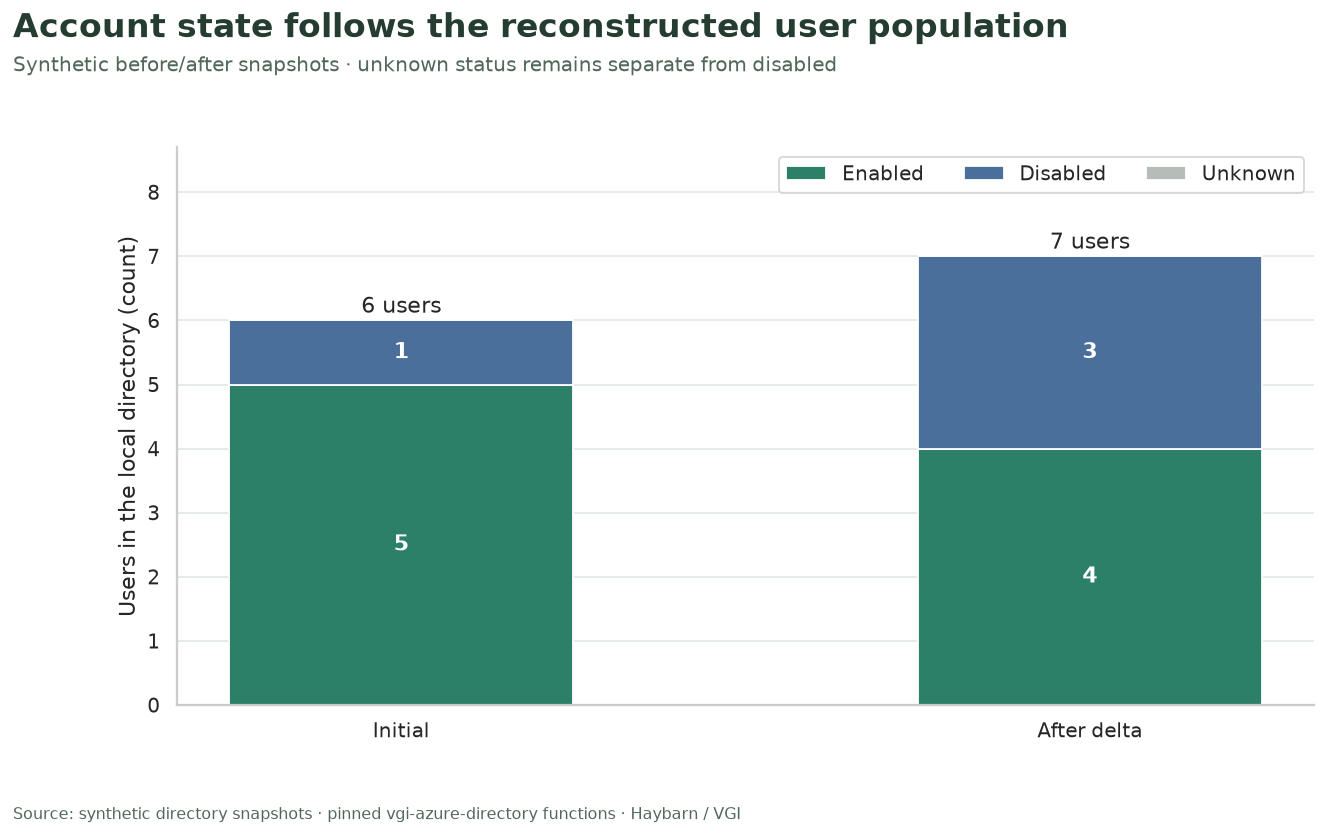

In [16]:
fig, ax = plt.subplots(figsize=(11.5, 6.5))
x = np.arange(len(states))
ax.bar(x, states.enabled, color="#2b8067", label="Enabled", width=0.5)
ax.bar(x, states.disabled, bottom=states.enabled, color="#4a6f9b", label="Disabled", width=0.5)
ax.bar(x, states.unknown, bottom=states.enabled + states.disabled, color="#b6bcb8", label="Unknown", width=0.5)
for i, row in states.iterrows():
    ax.text(i, row.users + 0.12, f"{row.users} users", ha="center")
    if row.enabled:
        ax.text(i, row.enabled / 2, str(row.enabled), ha="center", va="center", color="white", weight="bold")
    if row.disabled:
        ax.text(
            i, row.enabled + row.disabled / 2, str(row.disabled), ha="center", va="center", color="white", weight="bold"
        )
ax.set_xticks(x, states.snapshot)
ax.set_ylabel("Users in the local directory (count)")
ax.set_ylim(0, int(states.users.max()) + 1.7)
ax.set_yticks(range(int(states.users.max()) + 2))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncols=3)
finish(
    fig,
    "Account state follows the reconstructed user population",
    "Synthetic before/after snapshots · unknown status remains separate from disabled",
    f"states-removals-{REMOVED_USERS}.png",
)

## Replay the same delta to check idempotence

Suppose a caller must retry the old cursor. We request the same window again and apply the identical delete/upsert rules. The comparison checks every projected user field in both directions, not just the total count. It verifies this fixture’s replay behavior; it does not simulate a process crash or a real storage failure.

In [17]:
%%sql
CREATE TABLE replay_scan AS
SELECT * FROM azure.main.directory_users_delta(delta_token := '{{cursor}}');

DELETE FROM local_users
USING replay_scan r
WHERE local_users.id = r.id AND r._row_kind IS NULL AND r.change_type = 'removed';
INSERT OR REPLACE INTO local_users
SELECT id, user_principal_name, display_name, account_enabled
FROM replay_scan WHERE _row_kind IS NULL AND change_type = 'upsert';
UPDATE checkpoint SET delta_token = (
    SELECT _delta_next FROM replay_scan WHERE _row_kind = 'marker'
);


,Count


In [18]:
%%sql checks <<
SELECT
    (SELECT count(*) FROM (
        (SELECT * FROM local_users EXCEPT SELECT * FROM applied_once)
        UNION ALL
        (SELECT * FROM applied_once EXCEPT SELECT * FROM local_users)
    )) AS replay_state_differences,
    (SELECT count(*) FROM (
        (SELECT * FROM delta_scan EXCEPT SELECT * FROM replay_scan)
        UNION ALL
        (SELECT * FROM replay_scan EXCEPT SELECT * FROM delta_scan)
    )) AS replay_feed_differences,
    (SELECT count(*) FROM delta_scan WHERE _row_kind = 'marker') AS delta_markers,
    (SELECT count(*) FROM full_scan WHERE _row_kind = 'marker') AS full_markers,
    (SELECT count(*) - count(DISTINCT id) FROM local_users) AS duplicate_users,
    (SELECT count(*) FROM local_users WHERE id IS NULL) AS null_user_ids;

In [19]:
display(checks)
c = checks.iloc[0]
assert c.replay_state_differences == 0 and c.replay_feed_differences == 0
assert c.delta_markers == 1 and c.full_markers == 1
assert c.duplicate_users == 0 and c.null_user_ids == 0
assert b.current_users == b.initial_users + b.added_users - b.removed_users
assert ((states.enabled + states.disabled + states.unknown) == states.users).all()
prose("The replayed feed and final state are identical, markers are unique, and the user-count balance holds.")

,replay_state_differences,replay_feed_differences,delta_markers,full_markers,duplicate_users,null_user_ids
0,0,0,1,1,0,0


The replayed feed and final state are identical, markers are unique, and the user-count balance holds.

## Experiment: one additional removal

Change **`REMOVED_USERS = 1` to `2`**, restart and run all. Predict that the delta gains a removal row while the reconstructed directory loses one user. Compare the change-row chart, the headcount balance and the enabled/disabled totals. The replay checks should still pass.

The fixture removes an additional enabled account, so its status mix changes in a known way. That result is a controlled consequence of the synthetic input, not a measured tenant trend. Reset **`REMOVED_USERS = 1`** for the default; the runner can save the experiment separately.

In [20]:
connection.close()

[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)